<img src="../res/logo.jpg" alt="Volcanicus" width="50%">

# Rays

A **ray** is one direction of one scene: the radial profile of a single date/direction (one row of the source data). A scene holds 8 rays.

Looking at rays one by one tells *where* around the vent things happen, and isolates problems that only affect one direction. This notebook covers `rays_descriptors()`, residual saturation, and `flag_rays()` / `mask_rays()` to deal with corrupted rays. It builds on [scene_descriptors.ipynb](scene_descriptors.ipynb).

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import volcanicus
from volcanicus.constants import DIRECTION_ORDER, SATURATION_LEVEL

volcano = volcanicus.datasets.load("etna")
volcano

dates,100
missing,896
registers,792


## Ray descriptors

`rays_descriptors()` returns one row per ray, indexed by `(date, direction)`, always 8 rays per scene:

| descriptor | what it measures |
|---|---|
| `peak` | maximum residual along the ray |
| `efold_length` | meters past the peak over which the ray decays to `peak / e` (as for scenes) |
| `integrated` | residual integrated over the ray's annular sector (residual x m²) |
| `n_saturated` | number of bins at the saturation level (below) |
| `max_abs` | largest absolute residual, on the raw values |

In [2]:
rays = volcano.rays_descriptors()
print(rays.shape)
rays.head(8)

(800, 5)


peak  efold_length   integrated  n_saturated  max_abs
date       direction                                                         
2000-05-07 N          0.3256    244.447184  3038.784034            0   0.3256
           NE         0.3064     16.271219 -7646.828941            0   0.3064
           E          0.5932     28.045917 -2763.179964            0   0.5932
           SE         0.8099    124.694408  8210.336416            0   0.8099
           S          0.8163    204.853091  6636.268906            0   0.8163
           SO         0.3247    208.580232  7267.210666            0   0.3247
           O          0.2448     64.833843  3934.479588            0   0.2448
           NO         0.3778    186.675847 -2491.428273            0   0.3778

Rays add up to scenes: the 8 sector integrals of a scene sum to its `integrated`.

In [3]:
by_scene = rays["integrated"].groupby(level="date").sum(min_count=8)
scene_integrated = volcano.scenes_descriptors()["integrated"]
complete = by_scene.notna()
np.allclose(by_scene[complete], scene_integrated[complete])

True

## Where the heat is

Grouping the ray peaks by direction shows which side of the vent runs hotter. On Etna the typical (median) peak is fairly even all around, with the E to SO side a little hotter. The `azimuth` rose in [scene_descriptors.ipynb](scene_descriptors.ipynb), built from these same peaks, looks more lopsided (towards SE and S) because it weights every scene by its `anisotropy`: it shows where the heat goes *when one side clearly dominates*, not on a typical day.

Text(0.5, 1.0, 'Etna: median ray peak by direction')

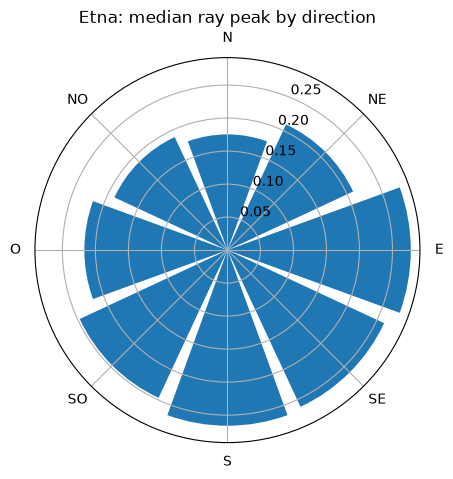

In [4]:
median_peak = rays["peak"].groupby(level="direction", sort=False).median()

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
bearings = np.radians(45.0 * np.arange(len(DIRECTION_ORDER)))
ax.bar(bearings, median_peak.reindex(DIRECTION_ORDER), width=np.radians(40))
ax.set_xticks(bearings, DIRECTION_ORDER)
ax.set_title("Etna: median ray peak by direction")

## Saturation

Positive residuals **saturate at exactly 1.0**. Across the bundled data, thousands of values sit right at 1.0 while barely any fall just below it, a pile-up no smooth distribution produces. It's concentrated on lava-dominated volcanoes such as Kilauea (this cell loads every dataset, it takes a few seconds):

In [5]:
counts = {}
for name in volcanicus.datasets.available():
    v = volcanicus.datasets.load(name)
    values = v.to_dataframe()[v.scenes_median.columns].to_numpy()
    counts[name] = {
        "== 1.0": int((values == SATURATION_LEVEL).sum()),
        "(0.99, 1.0)": int(((values > 0.99) & (values < 1)).sum()),
    }
counts = pd.DataFrame(counts).T
print("total:", counts.sum().to_dict())
counts.sort_values("== 1.0", ascending=False).head(8)

total: {'== 1.0': 5957, '(0.99, 1.0)': 6}


,== 1.0,"(0.99, 1.0)"
kilauea,1335,0
nyiragongo,1321,2
nyamuragira,644,1
erta_ale,617,0
fuego,442,0
ibu,410,0
etna,180,0
krakatau,170,0


The constant `SATURATION_LEVEL` holds that cap, and `n_saturated` counts how many bins of a ray sit at it. A saturated ray's `peak` is a floor, not the real anomaly: on Kilauea, many scenes are capped.

Text(0.5, 1.0, 'Kilauea')

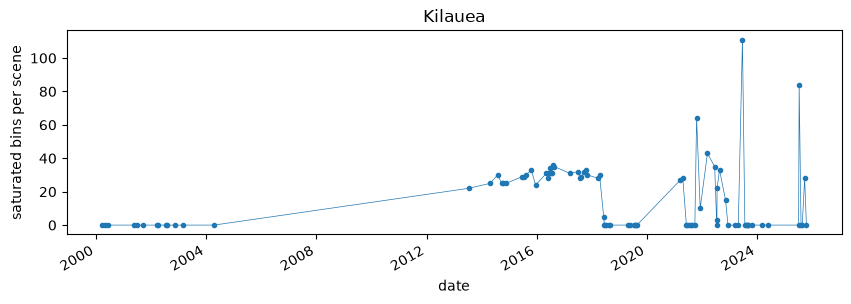

In [6]:
kilauea = volcanicus.datasets.load("kilauea")
kilauea_rays = kilauea.rays_descriptors()
saturated = kilauea_rays["n_saturated"].groupby(level="date").sum()

fig, ax = plt.subplots(figsize=(10, 3))
saturated.plot(ax=ax, marker=".", lw=0.5)
ax.set_ylabel("saturated bins per scene")
ax.set_title("Kilauea")

## Corrupted rays

Since nothing real goes beyond the saturation level, a residual *far* beyond it is a processing artifact. [scene_descriptors.ipynb](scene_descriptors.ipynb) showed the worst case: on Kadovar, 2018-05-27, the whole `NO` ray reads around −1000 while the other 7 directions look ordinary. On a symmetric log scale:

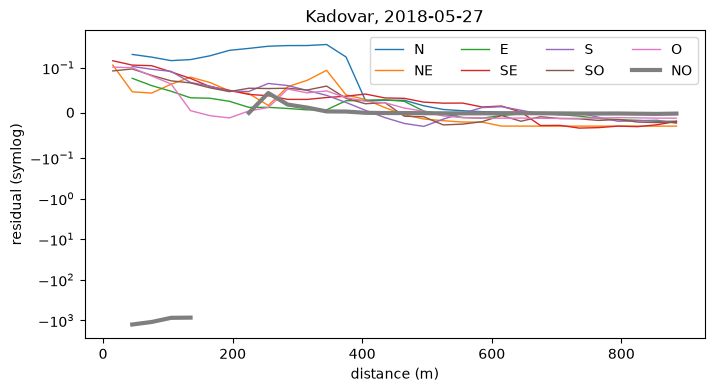

In [7]:
kadovar = volcanicus.datasets.load("kadovar")
bad_date = pd.Timestamp("2018-05-27")
scene = kadovar.to_scenes().loc[bad_date]
radii = [float(c.removesuffix("m")) for c in kadovar.scenes_median.columns]

fig, ax = plt.subplots(figsize=(8, 4))
for direction in DIRECTION_ORDER:
    ax.plot(
        radii,
        scene[direction].to_numpy(),
        lw=3 if direction == "NO" else 1,
        label=direction,
    )
ax.set_yscale("symlog", linthresh=0.1)
ax.set_xlabel("distance (m)")
ax.set_ylabel("residual (symlog)")
ax.set_title(f"Kadovar, {bad_date:%Y-%m-%d}")
ax.legend(ncol=4)

`flag_rays(limit=2.0)` flags every ray holding a residual larger than `limit` in absolute value. The default is twice the saturation level: it spares the values that only slightly overshoot 1.0 (there are some, up to ~1.03) and catches what's clearly off. On Kadovar it flags 11 rays, and they keep recurring in the same two directions, `N` and `NO`, across years: a direction-specific problem worth checking at the source.

In [8]:
flags = kadovar.flag_rays()
flagged = flags[flags].index
kadovar.rays_descriptors().loc[flagged, ["peak", "max_abs"]].round(2)

,,peak,max_abs
date,direction,,
2015-06-04,N,8.82,8.82
2015-07-22,N,13.31,13.31
2015-08-23,N,12.32,12.32
2015-09-24,N,13.12,13.12
2017-08-28,NO,0.01,7.40
2018-05-27,NO,0.04,1264.85
2018-07-30,NO,0.05,112.54
2024-08-15,NO,0.12,4.04
2024-09-24,NO,0.18,4.84


Across every dataset, and for a few other limits (this takes a few seconds):

In [9]:
limits = [1.5, 2.0, 3.0, 5.0]
rows = {}
for name in volcanicus.datasets.available():
    max_abs = volcanicus.datasets.load(name).rays_descriptors()["max_abs"]
    if (max_abs > limits[0]).any():
        rows[name] = {f"> {lim}": int((max_abs > lim).sum()) for lim in limits}
table = pd.DataFrame(rows).T
print("total flagged rays:", table.sum().to_dict())
table.sort_values("> 2.0", ascending=False)

total flagged rays: {'> 1.5': 41, '> 2.0': 26, '> 3.0': 19, '> 5.0': 12}


,> 1.5,> 2.0,> 3.0,> 5.0
kadovar,11,11,9,7
nyiragongo,3,3,3,2
nyamuragira,4,3,2,0
bogoslof,1,1,1,1
karangetang,3,1,1,1
copahue,1,1,0,0
kilauea,1,1,0,0
klyuchevskoy,2,1,1,0
ulawun,1,1,0,0
raikoke,1,1,1,1


The limit is a judgement call, which is why it's a parameter. Some volcanoes flagged at the default are lava-dominated (Kilauea, Nyamuragira, Klyuchevskoy), where a positive value of 3–4 *might* be a real but badly saturated measurement; raise the limit if you'd rather keep them. Large **negative** values (a vent several times colder than its surroundings) have no such excuse.

## Masking

`mask_rays(limit=2.0)` returns a new `Volcano` with every flagged ray blanked out (all its bins `NaN`). The whole ray goes, not only the offending values: the bins next to an absurd value are rarely trustworthy. The metadata records what was done:

In [10]:
kadovar_masked = kadovar.mask_rays()
kadovar_masked.metadata.masked_rays, kadovar_masked.metadata.mask_limit

(11, 2.0)

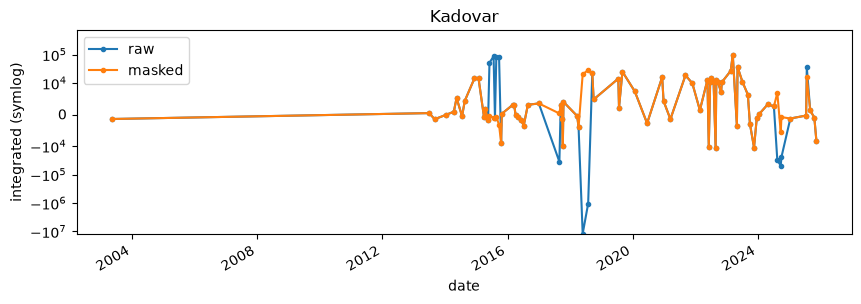

In [11]:
fig, ax = plt.subplots(figsize=(10, 3))
kadovar.scenes_descriptors()["integrated"].plot(ax=ax, marker=".", label="raw")
kadovar_masked.scenes_descriptors()["integrated"].plot(
    ax=ax, marker=".", label="masked"
)
ax.set_yscale("symlog", linthresh=1e4)
ax.set_ylabel("integrated (symlog)")
ax.set_title("Kadovar")
ax.legend()

A masked ray is just a missing ray from then on: reductions skip it, the scene's `anisotropy` and `azimuth` become `NaN` (a whole direction is missing), and `impute()` can fill it from its compass neighbors:

In [12]:
kadovar_masked.impute().scenes_descriptors().loc[bad_date].round(3)

peak                0.104
efold_length      325.307
integrated      26513.641
anisotropy          0.266
azimuth           349.833
Name: 2018-05-27 00:00:00, dtype: float64

## Next steps

- [scene_descriptors.ipynb](scene_descriptors.ipynb) for the scene-level descriptors.
- [tutorial.ipynb](tutorial.ipynb) for `impute()` and the rest of the `Volcano` API.